# SVM on Dataset2 (Portugese Class)

$\textit{by Anmol Anand (MS24063)}$

In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
from sklearn.feature_selection import mutual_info_classif
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay

In [2]:
df = pd.read_csv('student-por.csv', sep=';') 

df['pass'] = (df['G3'] >= 10).astype(int)

drop_cols = ['G3', 'pass']
X = df.drop(columns=drop_cols)
y = df['pass']

X = pd.get_dummies(X, drop_first=True)

X = X.astype(float)

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

mi_scores = mutual_info_classif(X_train, y_train, random_state=42)

mi_series = pd.Series(mi_scores, index=X_train.columns).sort_values(
    ascending=False
)

top_features = mi_series.head(10).index.tolist()
print('Selected Top Features via MI:', top_features)

X_train = X_train[top_features]
X_test = X_test[top_features]

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

Selected Top Features via MI: ['G2', 'G1', 'failures', 'higher_yes', 'school_MS', 'Medu', 'activities_yes', 'famrel', 'Fjob_services', 'Fedu']


In [4]:
param_grid = {
    'C': [0.1, 1, 10, 100],
    'gamma': ['scale', 'auto', 0.01, 0.1],
    'kernel': ['rbf', 'linear']
}

grid_search = GridSearchCV(SVC(probability=True, random_state=42), param_grid, cv=5, scoring='accuracy', n_jobs=-1)
grid_search.fit(X_train_scaled, y_train)

best_svm = grid_search.best_estimator_
print(f"Optimal Hyperparameters: {grid_search.best_params_}\n")


Optimal Hyperparameters: {'C': 1, 'gamma': 'scale', 'kernel': 'linear'}



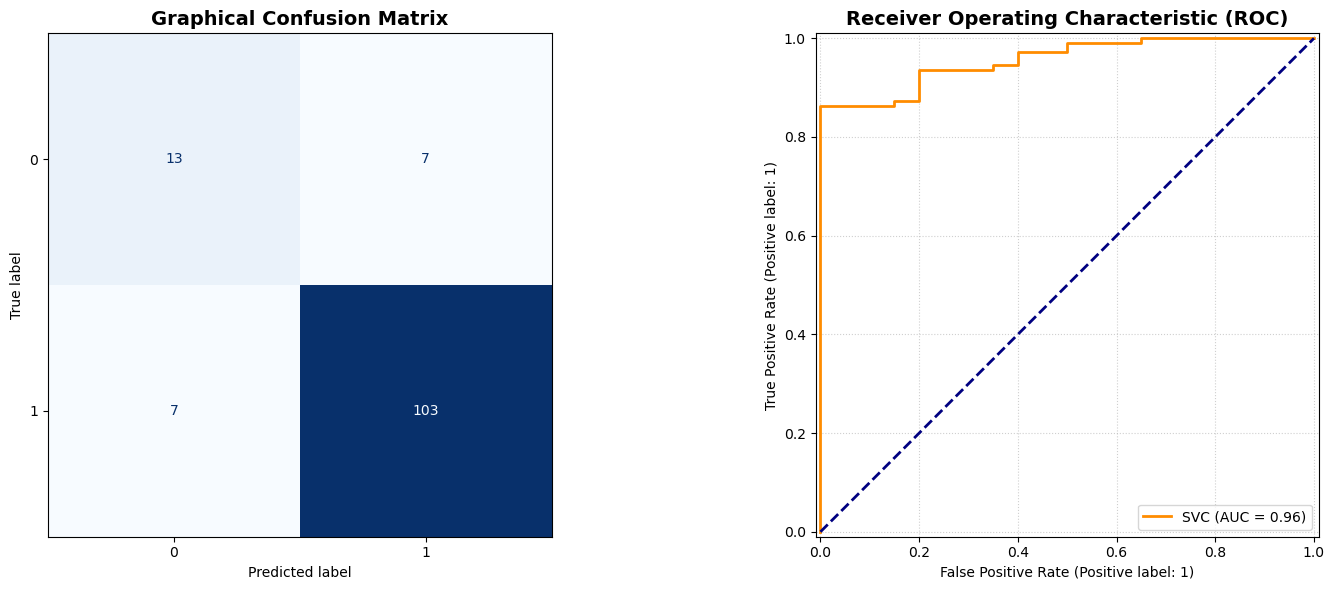

In [5]:

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

ConfusionMatrixDisplay.from_estimator(
    best_svm,  
    X_test_scaled,      
    y_test,           
    cmap='Blues',     
    ax=axes[0],        
    colorbar=False     
)
axes[0].set_title('Graphical Confusion Matrix', fontsize=14, fontweight='bold')
axes[0].grid(False)     

RocCurveDisplay.from_estimator(
    best_svm,          
    X_test_scaled,      
    y_test,             
    color='darkorange', 
    lw=2,               
    ax=axes[1]          
)

axes[1].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
axes[1].set_title('Receiver Operating Characteristic (ROC)', fontsize=14, fontweight='bold')
axes[1].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

In [6]:
y_pred = best_svm.predict(X_test_scaled)
y_prob = best_svm.predict_proba(X_test_scaled)[:, 1]

print("\n--- Classification Performance ---")
print(classification_report(y_test, y_pred))


--- Classification Performance ---
              precision    recall  f1-score   support

           0       0.65      0.65      0.65        20
           1       0.94      0.94      0.94       110

    accuracy                           0.89       130
   macro avg       0.79      0.79      0.79       130
weighted avg       0.89      0.89      0.89       130



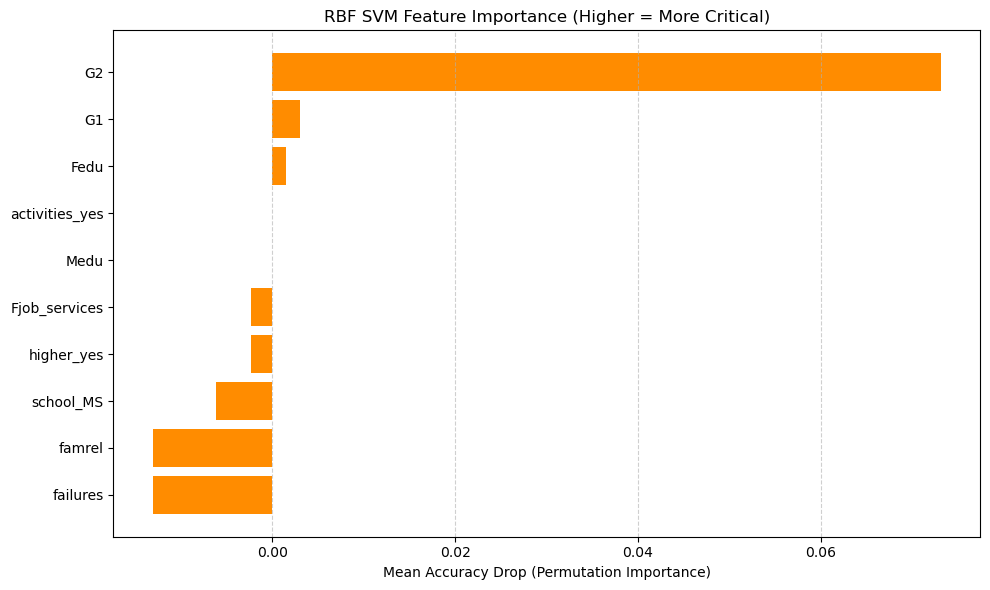

In [7]:
from sklearn.inspection import permutation_importance

best_model = grid_search.best_estimator_
winning_kernel = grid_search.best_params_['kernel']

plt.figure(figsize=(10, 6))

result = permutation_importance(best_model, X_test_scaled, y_test, n_repeats=10, random_state=42, n_jobs=-1)

importances = result.importances_mean
feature_names = X_train.columns

sorted_idx = np.argsort(importances)
sorted_names = feature_names[sorted_idx]
sorted_importances = importances[sorted_idx]

plt.barh(sorted_names, sorted_importances, color='darkorange')
plt.xlabel('Mean Accuracy Drop (Permutation Importance)')
plt.title('RBF SVM Feature Importance (Higher = More Critical)')

plt.grid(True, axis='x', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()